### Загрузка датасета и просмотр первых записей

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("data/shopease_raw_orders.csv")
df.head()

,OrderID,CustomerID,OrderDate,CustomerAge,Gender,City,Category,Product,Quantity,UnitPrice,Discount,PaymentMethod,OrderStatus,DeliveryDate,Rating,TotalAmount
0,18129,C0507,2026-02-01 23:39:00,68.0,Female,Alexandria,Electronics,Laptop,4,18000,0.0,Wallet,Delivered,2026-02-04 23:39:00,5.0,72000.0
1,11666,C0207,2026-03-03 10:37:00,21.0,Female,Cairo,Sports,Yoga Mat,2,600,0.1,Wallet,Delivered,2026-03-07 10:37:00,1.0,1080.0
2,12859,C1112,2026-05-23 17:57:00,23.0,Male,Aswan,Fashion,Shoes,-1,1500,10%,Bank Transfer,Delivered,2026-05-27 17:57:00,4.0,1350.0
3,19787,C1322,2026-01-29 07:51:00,23.0,Male,Tanta,Beauty,Hair Dryer,4,1300,0.1,Wallet,Delivered,2026-01-30 07:51:00,4.0,4680.0
4,16473,C0314,2026-06-23 20:17:00,62.0,Female,Tanta,Electronics,Laptop,1,18000,0.1,Mastercard,Delivered,2026-06-27 20:17:00,5.0,16200.0


### Анализ распределения возраста покупателей

Пропусков: 120
count    9900.000000
mean       44.381212
std        15.703142
min        -3.000000
25%        31.000000
50%        44.000000
75%        58.000000
max       150.000000
Name: CustomerAge, dtype: float64


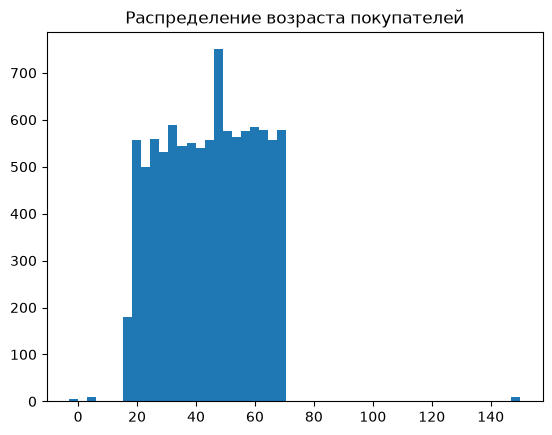

In [2]:
CUSTOMER_AGE_COL = "CustomerAge"

print(f"Пропусков: {df[CUSTOMER_AGE_COL].isna().sum()}")

print(df[CUSTOMER_AGE_COL].describe())

plt.hist(df[CUSTOMER_AGE_COL], bins=50)
plt.title("Распределение возраста покупателей")
plt.show()

### Анализ распределения количества товаров в заказе

count    10020.000000
mean         1.947605
std          1.100476
min         -3.000000
25%          1.000000
50%          2.000000
75%          3.000000
max          4.000000
Name: Quantity, dtype: float64


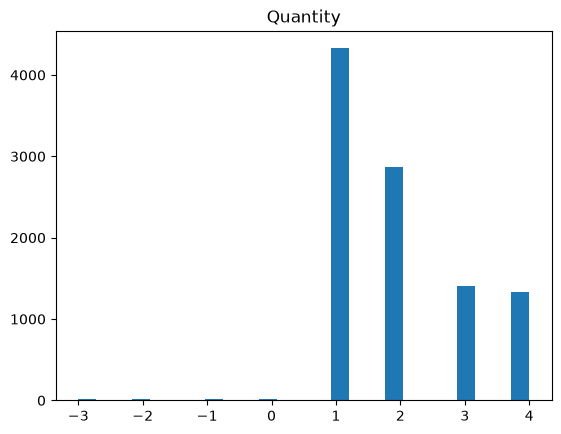

In [27]:
QUANTITY_COL = "Quantity"

print(df[QUANTITY_COL].describe())

plt.hist(df[QUANTITY_COL], bins=25)
plt.title(QUANTITY_COL)
plt.show()

### Анализ распределения цены за единицу товара

count     10020.000000
mean       1956.412176
std        5403.755496
min        -500.000000
25%         650.000000
50%         900.000000
75%        1500.000000
max      150000.000000
Name: UnitPrice, dtype: float64


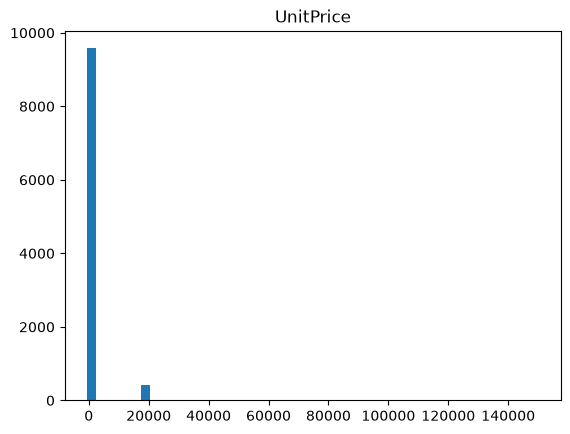

In [4]:
UNIT_PRICE_COL = "UnitPrice"

print(df[UNIT_PRICE_COL].describe())

plt.hist(df[UNIT_PRICE_COL], bins=50)
plt.title(UNIT_PRICE_COL)
plt.show()

### Сводная статистика по скидкам

Пропусков: 100
count     9920
unique      10
top        0.0
freq      3337
Name: Discount, dtype: object
Некорректных значений скидки: 0


count    9920.000000
mean        0.067838
std         0.061819
min         0.000000
25%         0.000000
50%         0.050000
75%         0.100000
max         0.200000
Name: Discount, dtype: float64

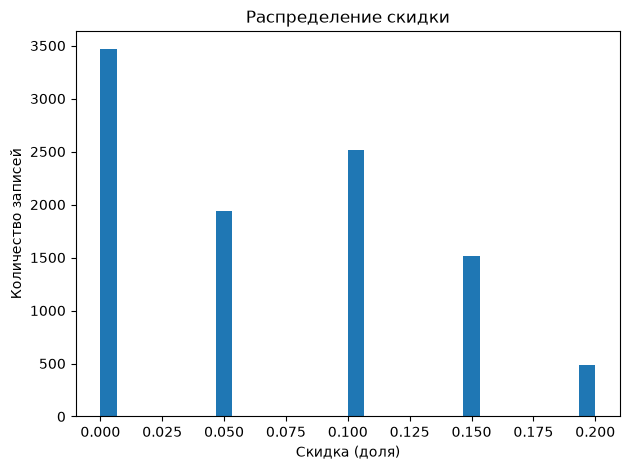

In [4]:
DISCOUNT_COL = "Discount"

print(f"Пропусков: {df[DISCOUNT_COL].isna().sum()}")

print(df[DISCOUNT_COL].describe())

discount_raw = df[DISCOUNT_COL].dropna().astype(str).str.strip()
discount_numeric = pd.to_numeric(discount_raw.str.rstrip("%"), errors="coerce")
discount_numeric.loc[discount_raw.str.endswith("%")] /= 100

print(f"Некорректных значений скидки: {discount_numeric.isna().sum()}")

display(discount_numeric.describe())

plt.hist(discount_numeric.dropna(), bins=30)
plt.title("Распределение скидки")
plt.xlabel("Скидка (доля)")
plt.ylabel("Количество записей")
plt.tight_layout()
plt.show()

### Анализ распределения оценок покупателей

count    7728.000000
mean        3.958851
std         1.023657
min        -1.000000
25%         3.000000
50%         4.000000
75%         5.000000
max         6.000000
Name: Rating, dtype: float64


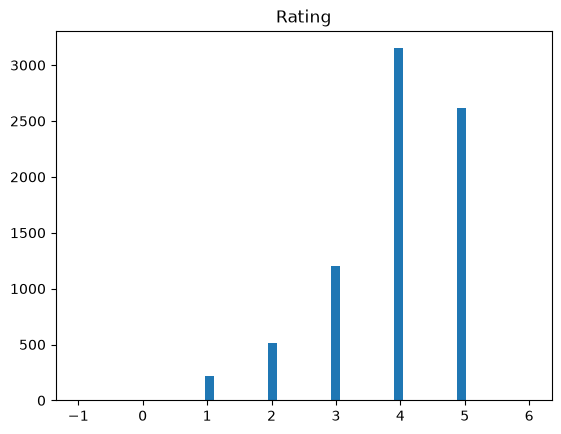

In [18]:
RATING_COL = "Rating"

print(df[RATING_COL].describe())

plt.hist(df[RATING_COL], bins=50)
plt.title(RATING_COL)
plt.show()

### Анализ распределения итоговой суммы заказа

count    10020.000000
mean      3308.779741
std       7328.702149
min        200.000000
25%        855.000000
50%       1600.000000
75%       2853.250000
max      72000.000000
Name: TotalAmount, dtype: float64


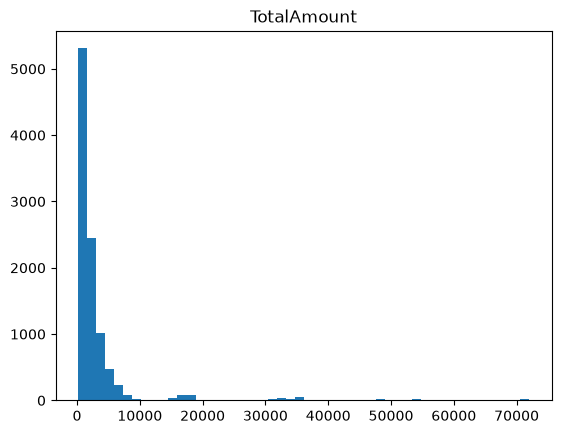

In [23]:
TOTAL_AMOUNT_COL = "TotalAmount"

print(df[TOTAL_AMOUNT_COL].describe())

plt.hist(df[TOTAL_AMOUNT_COL], bins=50)
plt.title(TOTAL_AMOUNT_COL)
plt.show()